# Background

- **Author**: RUEI-HSIANG, CHANG（張睿庠，B12303030；AI協助）
- **Created At**: 2026-11-11
- **Research Motivation and Context (why are we interested in the findings?)：** 使用者更正為G1–G6共同分群，並明確選189人完整觀察。精確輸入`data/processed/tk_g1_g6_complete_20261111.csv`，SHA `7683905c256c987844d112d003bdb2595fafe1efa41d6524e211e1db9f6f67eb`；[輸入文件](../data/processed/tk_g1_g6_20261111_documentation.ipynb)，[實際準備](../data/code/prepare_tk_g1_g6_complete_20261111.ipynb)。原210人中21議員缺年齡且全為G5首次參選，選擇偏差須揭露。合併／首長／議員三池維持；不依城市另跑，不放S策略、城市或公職種類入距離。歷史G5/G6四組合不再作本輪候選人類型。
- **Main Findings and Takeaways：** 已從乾淨kernel執行。G1–G6完整樣本189人；限定K=3–5及每群至少8人，候選主解為合併PAM三群48／77／64（silhouette 0.2322），議員PAM四群72／28／47／31（0.2508）；首長11人不選正式主解。K=2有更高silhouette，故群數未獲唯一支持；bootstrap及學歷敏感度顯示議員解不穩定。21缺年齡者全為首次參選，樣本選擇須揭露。
- **Future Direction：** 後續用S策略比較前應確認群組穩定、編碼政策與樣本涵蓋；不因分群使用的G欄差異而宣稱外部驗證。


In [1]:
from pathlib import Path
import hashlib,json,re
import numpy as np
import pandas as pd
from IPython.display import display,Markdown
for ROOT in (Path.cwd().resolve(),*Path.cwd().resolve().parents):
    if (ROOT/'AGENTS.md').is_file() and (ROOT/'templates').is_dir(): break
else: raise FileNotFoundError('請從專案目錄執行')
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def checked(rel,h):
    p=(ROOT/rel).resolve()
    assert p.is_relative_to((ROOT/'data/processed').resolve()) and p.is_file(),rel
    assert sha(p)==h,f'輸入版本改變：{rel}'
    return p
def save(frame,rel):
    p=(ROOT/rel).resolve(); assert p.is_relative_to((ROOT/'data/processed').resolve())
    frame.to_csv(p,index=False,encoding='utf-8-sig')
    q=pd.read_csv(p,dtype=str,keep_default_na=False)
    pd.testing.assert_frame_equal(frame.fillna('').astype(str).reset_index(drop=True),q,check_dtype=False)
    print(rel,len(q),len(q.columns),sha(p))

from scipy.cluster.hierarchy import linkage,cut_tree,dendrogram
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score,silhouette_samples,adjusted_rand_score
from itertools import combinations
import scipy,sklearn,matplotlib
import matplotlib.pyplot as plt
import time
print({'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__})
SEED=20261111
FEATURES=['G1_age','G2_sex_category','G3_education_category','G4_party_category','G5_first_candidacy','G6_family_search']
LABELS={'G1_age':'G1 年齡','G2_sex_category':'G2 來源性別','G3_education_category':'G3 公開學歷','G4_party_category':'G4 登記政黨','G5_first_candidacy':'G5 首次參選','G6_family_search':'G6 公職親屬搜尋'}


{'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'sklearn': '1.9.0'}


In [2]:
p=checked('data/processed/tk_g1_g6_complete_20261111.csv','7683905c256c987844d112d003bdb2595fafe1efa41d6524e211e1db9f6f67eb')
d=pd.read_csv(p,dtype=str,keep_default_na=False).sort_values('candidate_key').reset_index(drop=True)
d['G1_age']=pd.to_numeric(d.G1_age,errors='raise')
assert len(d)==189 and d.candidate_key.is_unique and d[FEATURES].notna().all().all()
assert d[FEATURES].astype(str).ne('').all().all()
POOLS={'all':d,'mayor':d[d.office_type=='直轄市長'].reset_index(drop=True),'council':d[d.office_type=='直轄市議員'].reset_index(drop=True)}
assert len(POOLS['mayor'])==11 and len(POOLS['council'])==178
AGE_RANGE=float(d.G1_age.max()-d.G1_age.min())
print('兩市合併189；首長11；議員178。年齡全距固定',AGE_RANGE,'歲，三池使用同一尺度。')
display(d[['candidate_key','candidate_name','county_city','office_type',*FEATURES]].head(10))


兩市合併189；首長11；議員178。年齡全距固定 59.0 歲，三池使用同一尺度。


,candidate_key,candidate_name,county_city,office_type,G1_age,G2_sex_category,G3_education_category,G4_party_category,G5_first_candidacy,G6_family_search
0,2026-C1-001,郭璽,臺北市,直轄市長,68,男,大學,其他政黨,0,0
1,2026-C1-002,沈伯洋,臺北市,直轄市長,44,男,研究所,民進黨,0,1
2,2026-C1-003,蕭文乾,臺北市,直轄市長,52,男,研究所,其他政黨,0,0
3,2026-C1-004,唐新民,臺北市,直轄市長,76,男,研究所,其他政黨,0,0
4,2026-C1-005,蔣萬安,臺北市,直轄市長,48,男,研究所,國民黨,0,1
5,2026-C1-006,林志成,臺北市,直轄市長,61,男,研究所,無黨籍／未經政黨推薦,0,0
6,2026-C1-019,張靜,高雄市,直轄市長,70,男,大學,其他政黨,0,0
7,2026-C1-020,賴瑞隆,高雄市,直轄市長,53,男,研究所,民進黨,0,0
8,2026-C1-021,王肇民,高雄市,直轄市長,63,男,大學,無黨籍／未經政黨推薦,1,0
9,2026-C1-022,柯志恩,高雄市,直轄市長,64,女,研究所,國民黨,0,1


## Summary statistics before clustering

In [3]:
age=d.G1_age
numeric=pd.DataFrame({'N':[age.count()],'missing_N':[age.isna().sum()],'mean':[age.mean()],'min':[age.min()],'q25':[age.quantile(.25)],'q50':[age.median()],'q75':[age.quantile(.75)],'max':[age.max()],'sd':[age.std()]},index=['G1 age'])
display(Markdown('**表1：G1年齡摘要，189人，單位歲。**'));display(numeric.round(2))
catrows=[]
for pool,q in POOLS.items():
 for col in FEATURES[1:]+['county_city','office_type','G3_unpublished_lowest_flag','eligibility_provisional_flag_20261108']:
  for val,n in q[col].value_counts().head(10).items():
   catrows.append({'pool':pool,'variable':col,'category':val,'N_nonmissing':len(q),'missing_N':0,'n':n,'percent':100*n/len(q)})
display(Markdown('**表2：各池使用類別與描述欄摘要；百分比分母各池全部完整觀察。**'));display(pd.DataFrame(catrows))
print('原210人有160曾參選、50首次；排除21名全是首次參選。完整樣本首次29/189，與原50/210不同，不能當隨機缺失。')


**表1：G1年齡摘要，189人，單位歲。**

,N,missing_N,mean,min,q25,q50,q75,max,sd
G1 age,189,0,50.53,24,42.0,49.0,59.0,83,11.9


**表2：各池使用類別與描述欄摘要；百分比分母各池全部完整觀察。**

,pool,variable,category,N_nonmissing,missing_N,n,percent
0,all,G2_sex_category,男,189,0,112,59.259259
1,all,G2_sex_category,女,189,0,77,40.740741
2,all,G3_education_category,研究所,189,0,119,62.962963
3,all,G3_education_category,大學,189,0,48,25.396825
4,all,G3_education_category,大學以下,189,0,22,11.640212
5,all,G4_party_category,國民黨,189,0,68,35.978836
6,all,G4_party_category,民進黨,189,0,61,32.275132
7,all,G4_party_category,無黨籍／未經政黨推薦,189,0,37,19.576720
8,all,G4_party_category,其他政黨,189,0,16,8.465608
9,all,G4_party_category,民眾黨,189,0,7,3.703704


原210人有160曾參選、50首次；排除21名全是首次參選。完整樣本首次29/189，與原50/210不同，不能當隨機缺失。


### The actual analysis starts below

Gower距離為六個欄位差異之等權平均：年齡差除以完整合併樣本全距，其餘五欄依原提案當類別，不同為1、相同為0。G5/G6是對稱二元，兩人同為搜尋負值也視為一致；不將0詮釋為已證明沒有親屬。G3主要版本沿用三類公開呈現分類作名目類別，另做低／大學／研究所的有序0/.5/1敏感度。三池固定同一年齡尺度，避免分池重標準化暗中改權重。

比較PAM（實際樣本medoid、最小化到最近medoid的距離總和）及average-linkage階層式分群（兩群所有成對距離平均）。PAM以BUILD加SWAP及9組固定seed隨機起點，共10起點，採最佳目標值；這是本Notebook透明Python實作，非聲稱呼叫已安裝R套件，也非全域最適保證。另用小樣本窮舉與單交換檢查。階層式傳入condensed Gower距離，不能把方距離矩陣當特徵。

K=2–5比較；依提案主範圍K=3–5且每群至少8人，按silhouette最高選候選主解，相同時較小K優先。K=2只作診斷。每種方法最佳可行解做200次bootstrap與30次列順序重排，再據穩定性限定結論；不以漂亮指標宣稱自然政治類型。首長N=11無法滿足最小8人要求，不選正式主解，所有K結果僅探索。

方法依據：[Gower混合變數與權重](https://stat.ethz.ch/R-manual/R-devel/library/cluster/html/daisy.html)、[PAM BUILD／SWAP](https://stat.ethz.ch/R-manual/R-devel/library/cluster/html/pam.html)、[SciPy average linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)。K-means的數值中心與GMM的Gaussian假設較不直接吻合這六欄混合資料，故主比較沿用提案已列的兩種方法；未把未執行方法寫為已比較。


In [4]:
def gower(frame, education_ordinal=False, excluded_education_flag=False):
    # Equal variable weights. Complete-case analysis; no pairwise omission/imputation.
    age=frame.G1_age.to_numpy(float)
    D=np.abs(age[:,None]-age[None,:])/AGE_RANGE
    for col in FEATURES[1:]:
        if col=='G3_education_category' and education_ordinal:
            z=frame[col].map({'大學以下':0,'大學':.5,'研究所':1}).to_numpy(float)
            D+=np.abs(z[:,None]-z[None,:])
        else:
            z=frame[col].to_numpy();D+=(z[:,None]!=z[None,:]).astype(float)
    D/=6
    np.fill_diagonal(D,0.)
    assert np.isfinite(D).all() and np.allclose(D,D.T) and D.min()>=0 and D.max()<=1
    return D

def pam_swap(D,initial):
    med=np.array(sorted(initial),dtype=int);n=len(D)
    while True:
        dm=D[:,med]; pos=np.argmin(dm,axis=1); near=dm[np.arange(n),pos]
        second=np.partition(dm,1,axis=1)[:,1]
        candidates=np.setdiff1d(np.arange(n),med)
        best_delta=-1e-10;best=None
        for slot in range(len(med)):
            base=np.where(pos==slot,second,near)
            costs=np.minimum(base[:,None],D[:,candidates]).sum(axis=0)
            j=int(np.argmin(costs));delta=float(costs[j]-near.sum())
            if delta<best_delta:
                best_delta=delta;best=(slot,int(candidates[j]))
        if best is None: break
        med[best[0]]=best[1];med.sort()
    labels=np.argmin(D[:,med],axis=1)
    # Each medoid represents itself in zero-distance ties; cost unchanged.
    labels[med]=np.arange(len(med))
    return labels,med,float(D[:,med].min(axis=1).sum())

def pam(D,k,seed=SEED,nstart=10):
    n=len(D);first=int(np.argmin(D.sum(axis=0)));med=[first]
    while len(med)<k:
        near=D[:,med].min(axis=1);c=np.setdiff1d(np.arange(n),med)
        costs=np.minimum(near[:,None],D[:,c]).sum(axis=0)
        med.append(int(c[np.argmin(costs)]))
    starts=[med];rng=np.random.default_rng(seed)
    starts.extend(rng.choice(n,k,replace=False).tolist() for _ in range(nstart-1))
    fits=[pam_swap(D,m) for m in starts]
    return min(fits,key=lambda z:(round(z[2],12),tuple(z[1])))

def canonical(labels,frame):
    groups={int(t):tuple(sorted(frame.loc[np.asarray(labels)==t,'candidate_key'])) for t in np.unique(labels)}
    order=sorted(groups,key=lambda t:groups[t])
    return np.array([order.index(int(t))+1 for t in labels])

def fit(D,k,method,frame,seed=SEED):
    if method=='PAM': labels,med,cost=pam(D,k,seed=seed)
    else:
        labels=cut_tree(linkage(squareform(D,checks=True),method='average'),n_clusters=k).ravel()
        med=np.array([np.flatnonzero(labels==v)[np.argmin(D[np.ix_(labels==v,labels==v)].sum(axis=0))] for v in np.unique(labels)])
        cost=float(D[:,med].min(axis=1).sum())
    labels=canonical(labels,frame)
    assert len(np.unique(labels))==k
    return labels,med,cost

# Independent numerical checks for custom PAM and mixed-data distance.
small=np.array([0.,.1,.2,3.,3.1,6.])
Dt=np.abs(small[:,None]-small[None,:]);lt,mt,ct=pam(Dt,2)
exact=min(Dt[:,list(c)].min(axis=1).sum() for c in combinations(range(len(Dt)),2))
assert np.isclose(ct,exact) and np.isclose(ct,Dt[:,mt].min(axis=1).sum())
for i in range(len(mt)):
 for h0 in set(range(len(Dt)))-set(mt):
  trial=mt.copy();trial[i]=h0
  assert Dt[:,trial].min(axis=1).sum()>=ct-1e-9
D0=gower(d)
for i,j in [(0,1),(2,10),(20,40)]:
 expected=(abs(d.G1_age.iloc[i]-d.G1_age.iloc[j])/AGE_RANGE+sum(d[c].iloc[i]!=d[c].iloc[j] for c in FEATURES[1:]))/6
 assert np.isclose(D0[i,j],expected)
print('PAM小樣本窮舉最適目標／所有單交換及Gower逐欄公式交叉檢查通過。正式樣本PAM為局部最小化，未宣稱全域最適。')


PAM小樣本窮舉最適目標／所有單交換及Gower逐欄公式交叉檢查通過。正式樣本PAM為局部最小化，未宣稱全域最適。


In [5]:
solutions={};diagnostics=[];long=[]
for pool,q in POOLS.items():
 D=gower(q)
 for method in ['PAM','Average linkage']:
  for k in range(2,6):
   labels,med,cost=fit(D,k,method,q)
   sizes=pd.Series(labels).value_counts()
   sil=silhouette_score(D,labels,metric='precomputed')
   eligible=(k in [3,4,5] and sizes.min()>=8)
   solutions[(pool,method,k)]={'labels':labels,'medoids':med,'D':D,'cost':cost}
   diagnostics.append({'pool':pool,'method':method,'k':k,'N':len(q),'silhouette':sil,'min_cluster_n':int(sizes.min()),'max_cluster_n':int(sizes.max()),'sizes':'|'.join(str(int(sizes.get(v,0))) for v in range(1,k+1)),'eligible_primary':eligible,'medoid_objective':cost})
   for i,r in q.iterrows(): long.append({'pool':pool,'method':method,'k':k,'candidate_key':r.candidate_key,'candidate_name':r.candidate_name,'cluster':int(labels[i])})
diag=pd.DataFrame(diagnostics);alls=pd.DataFrame(long)
# Main rule: maximum silhouette among K=3..5 with each cluster >=8.
# K=2 is a diagnostic, not silently substituted for the proposal's primary range.
selected={};method_best={}
for pool in POOLS:
 for method in ['PAM','Average linkage']:
  e=diag[(diag.pool==pool)&(diag.method==method)&diag.eligible_primary].sort_values(['silhouette','k'],ascending=[False,True])
  if len(e): method_best[(pool,method)]=int(e.iloc[0].k)
 e=diag[(diag.pool==pool)&diag.eligible_primary].sort_values(['silhouette','k','method'],ascending=[False,True,True])
 if len(e): selected[pool]=(e.iloc[0].method,int(e.iloc[0].k))
diag['selected_primary']=[selected.get(r.pool)==(r.method,r.k) for r in diag.itertuples()]
diag['method_best_eligible']=[method_best.get((r.pool,r.method))==r.k for r in diag.itertuples()]
display(Markdown('**表3：G1–G6模型與群數比較；K=2為診斷，主範圍K=3–5，最小群至少8人。**'));display(diag.round(4))
print('選擇規則產生的候選主解：',selected)
assert 'mayor' not in selected,'首長11人不可能形成每群至少8人之多群'


**表3：G1–G6模型與群數比較；K=2為診斷，主範圍K=3–5，最小群至少8人。**

,pool,method,k,N,silhouette,min_cluster_n,max_cluster_n,sizes,eligible_primary,medoid_objective,selected_primary,method_best_eligible
0,all,PAM,2,189,0.2653,73,116,116|73,False,48.8729,False,False
1,all,PAM,3,189,0.2322,48,77,48|77|64,True,41.8729,True,True
2,all,PAM,4,189,0.2291,39,62,39|62|46|42,True,38.2175,False,False
3,all,PAM,5,189,0.2158,24,52,28|52|40|45|24,True,34.6836,False,False
4,all,Average linkage,2,189,0.3094,8,181,181|8,False,59.4237,False,False
5,all,Average linkage,3,189,0.2302,3,181,181|5|3,False,56.7429,False,False
6,all,Average linkage,4,189,0.2600,3,103,103|78|5|3,False,45.7458,False,False
7,all,Average linkage,5,189,0.2625,3,103,103|50|5|3|28,False,41.5141,False,False
8,mayor,PAM,2,11,0.4272,2,9,9|2,False,2.0932,False,False
9,mayor,PAM,3,11,0.5196,2,6,6|3|2,False,1.2486,False,False


選擇規則產生的候選主解： {'all': ('PAM', 3), 'council': ('PAM', 4)}


## Stability diagnostics

In [6]:
B=200;ORDER_REPEATS=30
stable=[];orders=[]
for (pool,method),k in method_best.items():
 q=POOLS[pool];sol=solutions[(pool,method,k)];D=sol['D'];base=sol['labels'];rng=np.random.default_rng(SEED)
 groups={v:set(np.flatnonzero(base==v)) for v in np.unique(base)}
 jacc={v:[] for v in groups};ari=[]
 for b in range(B):
  draw=rng.integers(0,len(q),len(q));support=set(draw.tolist())
  qb=q.iloc[draw].reset_index(drop=True);Db=D[np.ix_(draw,draw)]
  lab,_,_=fit(Db,k,method,qb,seed=SEED+b)
  # Assign every original candidate to closest bootstrap medoid for comparable full-sample ARI.
  bootmed=[]
  for v in np.unique(lab):
   ids=np.flatnonzero(lab==v);bootmed.append(draw[ids[np.argmin(Db[np.ix_(ids,ids)].sum(axis=0))]])
  pred=np.argmin(D[:,bootmed],axis=1);ari.append(adjusted_rand_score(base,pred))
  bootgroups=[set(draw[lab==v].tolist()) for v in np.unique(lab)]
  for v,g in groups.items():
   target=g&support
   if target:
    jacc[v].append(max(len(target&bg)/len(target|bg) for bg in bootgroups))
 for v,js in jacc.items():
  stable.append({'pool':pool,'method':method,'k':k,'cluster':int(v),'original_n':len(groups[v]),'B':B,'present_replicates':len(js),'jaccard_common_support_mean':np.mean(js),'jaccard_q025':np.quantile(js,.025),'jaccard_q975':np.quantile(js,.975),'projected_ARI_mean':np.mean(ari),'projected_ARI_q025':np.quantile(ari,.025),'projected_ARI_q975':np.quantile(ari,.975)})
 for b in range(ORDER_REPEATS):
  perm=rng.permutation(len(q));lab,_,_=fit(D[np.ix_(perm,perm)],k,method,q.iloc[perm].reset_index(drop=True))
  back=np.empty(len(q),int);back[perm]=lab
  orders.append({'pool':pool,'method':method,'k':k,'repeat':b+1,'ARI':adjusted_rand_score(base,back)})
 print('stability complete',pool,method,k,flush=True)
stability_df=pd.DataFrame(stable);order_df=pd.DataFrame(orders)
display(Markdown('**表4：各方法最佳可行解之200次bootstrap；Jaccard在抽到成員集合比較，分位數為穩定性分布，非母體參數信賴區間。**'));display(stability_df.round(3))
display(order_df.groupby(['pool','method','k']).ARI.agg(['min','mean',lambda x:np.mean(np.isclose(x,1))]).round(3))


stability complete all PAM 3


stability complete council PAM 4


stability complete council Average linkage 3


**表4：各方法最佳可行解之200次bootstrap；Jaccard在抽到成員集合比較，分位數為穩定性分布，非母體參數信賴區間。**

,pool,method,k,cluster,original_n,B,present_replicates,jaccard_common_support_mean,jaccard_q025,jaccard_q975,projected_ARI_mean,projected_ARI_q025,projected_ARI_q975
0,all,PAM,3,1,48,200,200,0.636,0.250,1.000,0.607,0.171,1.000
1,all,PAM,3,2,77,200,200,0.727,0.343,1.000,0.607,0.171,1.000
2,all,PAM,3,3,64,200,200,0.805,0.375,1.000,0.607,0.171,1.000
3,council,PAM,4,1,72,200,200,0.645,0.300,0.958,0.438,0.110,0.827
4,council,PAM,4,2,28,200,200,0.498,0.173,1.000,0.438,0.110,0.827
5,council,PAM,4,3,47,200,200,0.604,0.263,0.889,0.438,0.110,0.827
6,council,PAM,4,4,31,200,200,0.369,0.179,0.809,0.438,0.110,0.827
7,council,Average linkage,3,1,141,200,200,0.761,0.520,0.873,0.309,0.102,0.613
8,council,Average linkage,3,2,9,200,200,0.471,0.100,1.000,0.309,0.102,0.613
9,council,Average linkage,3,3,28,200,200,0.187,0.119,0.413,0.309,0.102,0.613


min   mean  <lambda_0>
pool    method          k                          
all     PAM             3  0.985  0.993       0.567
council Average linkage 3  0.271  0.455       0.233
        PAM             4  1.000  1.000       1.000

## Group characteristics and coding sensitivity

In [7]:
assignment_rows=[];profile_rows=[];sensitivity=[]
rng=np.random.default_rng(SEED)
for pool,(method,k) in selected.items():
 q=POOLS[pool];sol=solutions[(pool,method,k)];labels=sol['labels'];sil=silhouette_samples(sol['D'],labels,metric='precomputed')
 for i,r in q.iterrows():
  rec=r.to_dict();rec.update(pool=pool,method=method,k=k,cluster=f'C{labels[i]}',silhouette=sil[i],is_medoid=int(i in sol['medoids']))
  assignment_rows.append(rec)
 for v in np.unique(labels):
  sub=q[labels==v];age=sub.G1_age.to_numpy(float);means=rng.choice(age,size=(2000,len(age)),replace=True).mean(axis=1);lo,hi=np.quantile(means,[.025,.975])
  for col in FEATURES[1:]:
   for val,n in sub[col].value_counts().items(): profile_rows.append({'pool':pool,'method':method,'k':k,'cluster':f'C{v}','cluster_n':len(sub),'variable':col,'category':val,'n':int(n),'percent':100*n/len(sub),'age_mean':age.mean(),'age_sd':age.std(ddof=1),'age_median':np.median(age),'age_mean_ci_low':lo,'age_mean_ci_high':hi})
 # Ordinal education: explicitly a sensitivity, not recoding the primary definition.
 Do=gower(q,education_ordinal=True);lo,_,_=fit(Do,k,method,q)
 sensitivity.append({'pool':pool,'check':'education_ordinal_at_fixed_method_K','N':len(q),'method':method,'k':k,'ARI_vs_primary_common_candidates':adjusted_rand_score(labels,lo)})
 # Remove only previously flagged unpublished education values; keep primary intact.
 keep=q.G3_unpublished_lowest_flag.ne('1').to_numpy();qs=q.loc[keep].reset_index(drop=True)
 ls,_,_=fit(gower(qs),k,method,qs)
 sensitivity.append({'pool':pool,'check':'exclude_unpublished_education_flag_at_fixed_method_K','N':len(qs),'method':method,'k':k,'ARI_vs_primary_common_candidates':adjusted_rand_score(labels[keep],ls)})
 # Compare the two algorithms at the selected K, not unrelated label names.
 other='Average linkage' if method=='PAM' else 'PAM'
 sensitivity.append({'pool':pool,'check':'other_algorithm_same_K','N':len(q),'method':other,'k':k,'ARI_vs_primary_common_candidates':adjusted_rand_score(labels,solutions[(pool,other,k)]['labels'])})
assign=pd.DataFrame(assignment_rows);profiles_df=pd.DataFrame(profile_rows);sens=pd.DataFrame(sensitivity)
display(Markdown('**表5：所選候選主解之背景特徵（分群使用的欄位，僅為群組解讀，非獨立驗證或差異檢定）。**'))
for pool in selected:
 a=assign[assign.pool==pool]
 display(a.groupby('cluster').agg(N=('candidate_key','size'),age_mean=('G1_age','mean'),age_sd=('G1_age','std'),age_median=('G1_age','median')))
 for c in FEATURES[1:]: display(pd.crosstab(a.cluster,a[c],normalize='index').mul(100).round(1))
display(Markdown('**表6：學歷定義、未公開政策碼與替代演算法敏感度；ARI=1表示相同分割。**'));display(sens.round(3))


**表5：所選候選主解之背景特徵（分群使用的欄位，僅為群組解讀，非獨立驗證或差異檢定）。**

,N,age_mean,age_sd,age_median
cluster,,,,
C1,48,57.187500,12.436488,60.0
C2,77,49.155844,10.833750,49.0
C3,64,47.203125,10.892228,47.0


G2_sex_category,女,男
cluster,,
C1,25.0,75.0
C2,20.8,79.2
C3,76.6,23.4


G3_education_category,大學,大學以下,研究所
cluster,,,
C1,56.2,29.2,14.6
C2,10.4,5.2,84.4
C3,20.3,6.2,73.4


G4_party_category,其他政黨,國民黨,民眾黨,民進黨,無黨籍／未經政黨推薦
cluster,,,,,
C1,16.7,16.7,8.3,6.2,52.1
C2,9.1,19.5,1.3,62.3,7.8
C3,1.6,70.3,3.1,15.6,9.4


G5_first_candidacy,0,1
cluster,,
C1,85.4,14.6
C2,80.5,19.5
C3,89.1,10.9


... (5 outputs left out)

G5_first_candidacy,0,1
cluster,,
C1,80.6,19.4
C2,85.7,14.3
C3,89.4,10.6
C4,87.1,12.9


G6_family_search,0,1
cluster,,
C1,87.5,12.5
C2,85.7,14.3
C3,21.3,78.7
C4,74.2,25.8


**表6：學歷定義、未公開政策碼與替代演算法敏感度；ARI=1表示相同分割。**

,pool,check,N,method,k,ARI_vs_primary_common_candidates
0,all,education_ordinal_at_fixed_method_K,189,PAM,3,0.801
1,all,exclude_unpublished_education_flag_at_fixed_me...,184,PAM,3,1.000
2,all,other_algorithm_same_K,189,Average linkage,3,0.008
3,council,education_ordinal_at_fixed_method_K,178,PAM,4,0.428
4,council,exclude_unpublished_education_flag_at_fixed_me...,173,PAM,4,0.333
5,council,other_algorithm_same_K,178,Average linkage,4,0.176


## Figures

模型圖為描述指標，不加虛構信賴區間；年齡平均附條件於已擬合群別的bootstrap 95%區間，未涵蓋群別選擇不確定性。群人數是樣本計數。

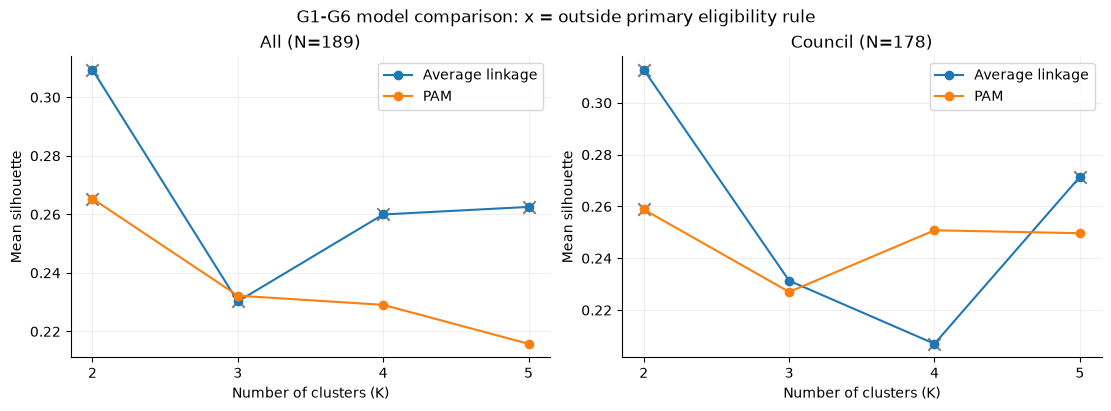

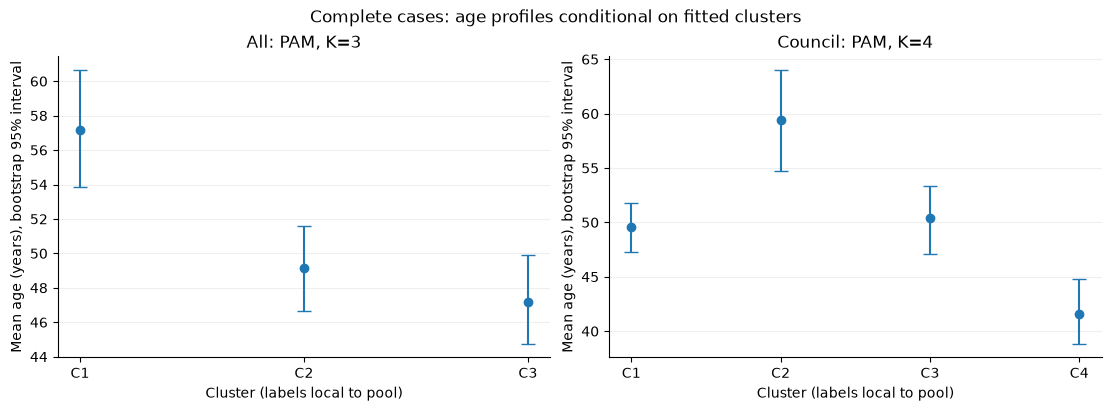

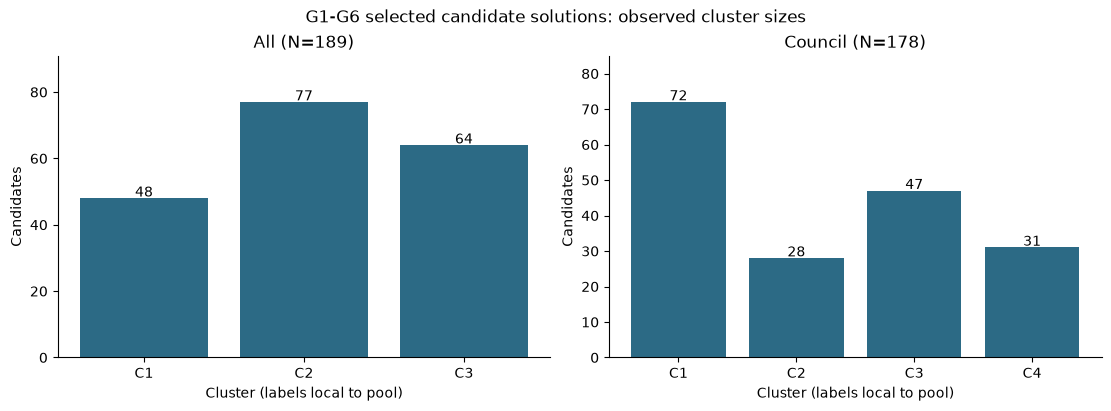

In [8]:
ASSET=ROOT/'finding/taipei_kaohsiung_g1_g6_model_comparison_20261111_assets';ASSET.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,pool in zip(axes,['all','council']):
 for method,g in diag[diag.pool==pool].groupby('method'):
  ax.plot(g.k,g.silhouette,marker='o',label=method)
  bad=g[~g.eligible_primary];ax.scatter(bad.k,bad.silhouette,marker='x',s=80,color='gray')
 ax.set(title=f'{pool.title()} (N={len(POOLS[pool])})',xlabel='Number of clusters (K)',ylabel='Mean silhouette',xticks=[2,3,4,5]);ax.legend();ax.grid(alpha=.2)
fig.suptitle('G1-G6 model comparison: x = outside primary eligibility rule')
fig.savefig(ASSET/'model_comparison.png',dpi=160);plt.show();plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,pool in zip(axes,['all','council']):
 if pool not in selected: ax.set_axis_off();continue
 a=assign[assign.pool==pool];p=profiles_df[(profiles_df.pool==pool)&(profiles_df.variable=='G2_sex_category')].drop_duplicates('cluster').set_index('cluster')
 ids=sorted(a.cluster.unique());mu=[p.loc[c,'age_mean'] for c in ids];low=[p.loc[c,'age_mean_ci_low'] for c in ids];high=[p.loc[c,'age_mean_ci_high'] for c in ids]
 ax.errorbar(ids,mu,yerr=[np.array(mu)-low,np.array(high)-mu],fmt='o',capsize=5)
 ax.set(title=f'{pool.title()}: {selected[pool][0]}, K={selected[pool][1]}',xlabel='Cluster (labels local to pool)',ylabel='Mean age (years), bootstrap 95% interval');ax.grid(axis='y',alpha=.2)
fig.suptitle('Complete cases: age profiles conditional on fitted clusters')
fig.savefig(ASSET/'age_profiles.png',dpi=160);plt.show();plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,pool in zip(axes,['all','council']):
 if pool not in selected: ax.set_axis_off();continue
 a=assign[assign.pool==pool];counts=a.cluster.value_counts().sort_index()
 ax.bar(counts.index,counts.values,color='#2C6A85')
 for i,n in enumerate(counts): ax.text(i,n+.5,str(n),ha='center')
 ax.set(title=f'{pool.title()} (N={len(a)})',xlabel='Cluster (labels local to pool)',ylabel='Candidates');ax.set_ylim(0,counts.max()*1.18)
fig.suptitle('G1-G6 selected candidate solutions: observed cluster sizes')
fig.savefig(ASSET/'cluster_sizes.png',dpi=160);plt.show();plt.close(fig)


## Saved outputs and verification

In [9]:
OUTPUTS={'diagnostics': 'data/processed/tk_g1_g6_model_diagnostics_20261111.csv', 'all_solutions': 'data/processed/tk_g1_g6_all_solutions_20261111.csv', 'selected_assignments': 'data/processed/tk_g1_g6_selected_assignments_20261111.csv', 'profiles': 'data/processed/tk_g1_g6_profiles_20261111.csv', 'stability': 'data/processed/tk_g1_g6_bootstrap_20261111.csv', 'order': 'data/processed/tk_g1_g6_order_sensitivity_20261111.csv', 'sensitivity': 'data/processed/tk_g1_g6_coding_sensitivity_20261111.csv'}
frames={'diagnostics':diag,'all_solutions':alls,'selected_assignments':assign,'profiles':profiles_df,'stability':stability_df,'order':order_df,'sensitivity':sens}
assert not alls.duplicated(['pool','method','k','candidate_key']).any()
assert not assign.duplicated(['pool','candidate_key']).any()
assert len(alls)==(189+11+178)*8
assert len(assign)==sum(len(POOLS[p]) for p in selected)
assert assign[FEATURES].notna().all().all()
for k,f in frames.items(): save(f,OUTPUTS[k])
assert sha(ROOT/'data/processed/tk_g1_g6_complete_20261111.csv')=='7683905c256c987844d112d003bdb2595fafe1efa41d6524e211e1db9f6f67eb'
print('驗證通過；每個解均使用六欄，不讀取S欄，不將分群欄差異當獨立假說檢定。')


data/processed/tk_g1_g6_model_diagnostics_20261111.csv 24 12 8e55d57e9051b7ebcec3e2fcf7f3e3a160ae16f1ce9fb9261c162d070b6fd8fa
data/processed/tk_g1_g6_all_solutions_20261111.csv 3024 6 bf6974cc316147d2d0eb2b1b5248225a5b392295f4d0d81f953d52a83ed17501
data/processed/tk_g1_g6_selected_assignments_20261111.csv 367 65 94bbf914ee8787d64af0b37ac14a638b50a5d4771515778a7b5e9740f402cf0c
data/processed/tk_g1_g6_profiles_20261111.csv 95 14 9527c711c65cc5a37f7f901150d6aa423f610f524f8c6415bf6d7ae4573b307d
data/processed/tk_g1_g6_bootstrap_20261111.csv 10 13 a5dc8159cda7244bca0c45664030b4e1b3dad6e81bdac9446f2e9e1b1d673e3b
data/processed/tk_g1_g6_order_sensitivity_20261111.csv 90 5 e25a28e478d094e43437d5db8478e7c2298e1d8695c6bc6cf59874505be3a3a1
data/processed/tk_g1_g6_coding_sensitivity_20261111.csv 6 6 57cf42a18ffb6900903528b8f8d07031ee1fd7b667a11861a0913e87aa3c2536
驗證通過；每個解均使用六欄，不讀取S欄，不將分群欄差異當獨立假說檢定。


## Interpretation and limits

本輪所有解確實使用G1年齡、G2性別、G3公開學歷、G4登記政黨、G5首次參選、G6公職親屬搜尋六欄。使用者選完整觀察，因此210→189，排除21人全為G5首次參選議員；首次比例50/210=23.8%→29/189=15.3%。這不是隨機抽樣損失，不能代表原210人或全臺候選人。

在提案主範圍K=3–5及每群至少8人的條件下：合併PAM K=3（48／77／64人，silhouette 0.2322）；議員PAM K=4（72／28／47／31人，0.2508）。合併average linkage的K=3–5皆有3人小群，未達人數規則；議員average linkage只有K=3可行（141／9／28，0.2313）。首長N=11無法符合多群每群至少8人，未選正式主解，只保留K=2–5探索結果。

**此處選的是限定條件下的候選解，不是所有K／所有方法的全域最佳。** K=2的silhouette其實較高：合併PAM 0.2653、average linkage 0.3094（181／8）；議員PAM 0.2588、average linkage 0.3128（169／9）。依提案既定主範圍本輪將K=2列替代診斷，不隱藏此結果，也不據此說3群／4群已獲唯一支持。

200次bootstrap中，合併PAM各群共同抽樣成員Jaccard約0.636／0.727／0.805；議員PAM約0.645／0.498／0.604／0.369。尤其議員有不穩定群。30次列序重排合併PAM平均ARI 0.993、最低0.985；議員PAM均1。列序穩定不等於抽樣穩定。

G3改作有序類別，與主解ARI為合併0.801、議員0.428；排除5筆未公開學歷政策碼後為合併1.000、議員0.333。顯示議員分群依賴學歷處理，不宜將這4群定為已確立類型。G3主版本分類沿用先前公開呈現規則，不等於學位認證。

合併候選解的C1平均57.2歲、25/48無黨籍／未推薦、研究所7/48；C2平均49.2歲、研究所65/77、男性61/77、民進黨48/77；C3平均47.2歲、女性49/64、國民黨45/64、G6正值48/64。這些是參與分群欄位的樣本描述，不是外部驗證、策略差異或因果結論。C碼只在同池同解內有意義，不能跨池視為同一類。

目前應採**G1–G6探索性分群與方法比較**的表述，尤其議員結果需要保留多解敏感度。尚未用S策略判斷群數或挑選結果。原S1工作單仍為210人及舊P碼來源快照；新群別另存selected_assignments，不將缺年齡的21人任意分入新群。原G5/G6 finding Notebook、伴隨報告與圖檔已依使用者要求移除；底層資料保留。11/10舊簡報未更新。
